In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Sklearn pipelines and preprocessing
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Models
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier

# Metrics
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    average_precision_score,
    roc_curve,
    precision_recall_curve
)

# Plot settings
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
%matplotlib inline

In [4]:
# Load dataset
df = pd.read_csv("../Predictive Maintenance/ai4i2020.csv")

print(f"Dataset Shape: {df.shape}")
print("-" * 50)
print("Data Types & Null Counts:")
print(df.info())
print("-" * 50)
display(df.head())

Dataset Shape: (10000, 14)
--------------------------------------------------
Data Types & Null Counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  object 
 2   Type                     10000 non-null  object 
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [5]:
# Target counts
failure_counts = df['Machine failure'].value_counts()
failure_pct = df['Machine failure'].value_counts(normalize=True) * 100

print(f"Non-Failures (0): {failure_counts[0]} ({failure_pct[0]:.2f}%)")
print(f"Failures (1):     {failure_counts[1]} ({failure_pct[1]:.2f}%)")

# Specific failure mode breakdown
modes = ['TWF', 'HDF', 'PWF', 'OSF', 'RNF']
print("\nFailure breakdown by mode:")
print(df[modes].sum())

Non-Failures (0): 9661 (96.61%)
Failures (1):     339 (3.39%)

Failure breakdown by mode:
TWF     46
HDF    115
PWF     95
OSF     98
RNF     19
dtype: int64


In [6]:
# Create physically grounded features
df_feat = df.copy()

# 1. Temperature difference (Heat dissipation indicator)
df_feat['Temp_diff'] = df_feat['Process temperature [K]'] - df_feat['Air temperature [K]']

# 2. Mechanical Power (W) = Torque (N*m) * Angular velocity (rad/s)
df_feat['Power_W'] = df_feat['Torque [Nm]'] * (df_feat['Rotational speed [rpm]'] * (2 * np.pi / 60))

# 3. Torque x Tool Wear interaction (Overstrain indicator)
df_feat['Torque_Wear_Ratio'] = df_feat['Torque [Nm]'] * df_feat['Tool wear [min]']

print("Engineered feature summary:")
display(df_feat[['Temp_diff', 'Power_W', 'Torque_Wear_Ratio']].describe().T)

Engineered feature summary:


,count,mean,std,min,25%,50%,75%,max
Temp_diff,10000.0,10.000630,1.001094,7.60000,9.300000,9.800000,11.000000,12.100000
Power_W,10000.0,6279.744953,1067.418295,1148.44061,5561.184484,6271.027344,7003.002724,10469.923005
Torque_Wear_Ratio,10000.0,4314.664550,2826.567692,0.00000,1963.650000,4012.950000,6279.000000,16497.000000


In [7]:
# Target variable
y = df_feat['Machine failure']

# Drop identifiers and breakdown failure indicators (they directly cause target leakage)
drop_cols = ['UDI', 'Product ID', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF']
X = df_feat.drop(columns=drop_cols)

# Stratified split: preserves the 3.39% failure ratio in both train and test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"X_train shape: {X_train.shape} | Failures: {y_train.sum()} ({y_train.mean():.3%})")
print(f"X_test shape:  {X_test.shape}  | Failures: {y_test.sum()} ({y_test.mean():.3%})")

X_train shape: (8000, 9) | Failures: 271 (3.388%)
X_test shape:  (2000, 9)  | Failures: 68 (3.400%)


In [8]:
# Identify column categories
categorical_cols = ['Type']
numeric_cols = [col for col in X_train.columns if col != 'Type']

# Numeric scaler and categorical one-hot encoder
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_cols),
        ('cat', OneHotEncoder(drop='first', sparse_output=False), categorical_cols)
    ]
)

In [9]:
# Define candidate models
models = {
    'Logistic Regression': Pipeline([
        ('prep', preprocessor),
        ('clf', LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42))
    ]),
    'Random Forest': Pipeline([
        ('prep', preprocessor),
        ('clf', RandomForestClassifier(n_estimators=200, class_weight='balanced', random_state=42, n_jobs=-1))
    ]),
    'HistGradientBoosting': Pipeline([
        ('prep', preprocessor),
        ('clf', HistGradientBoostingClassifier(class_weight='balanced', random_state=42))
    ])
}

# Evaluate with Stratified 5-Fold CV
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = ['roc_auc', 'average_precision', 'f1', 'recall']

cv_results = {}
for name, model in models.items():
    res = cross_validate(model, X_train, y_train, cv=cv, scoring=scoring)
    cv_results[name] = {
        'ROC-AUC': f"{res['test_roc_auc'].mean():.4f} +/- {res['test_roc_auc'].std():.4f}",
        'PR-AUC': f"{res['test_average_precision'].mean():.4f} +/- {res['test_average_precision'].std():.4f}",
        'F1-Score': f"{res['test_f1'].mean():.4f} +/- {res['test_f1'].std():.4f}",
        'Recall': f"{res['test_recall'].mean():.4f} +/- {res['test_recall'].std():.4f}"
    }

pd.DataFrame(cv_results).T

,ROC-AUC,PR-AUC,F1-Score,Recall
Logistic Regression,0.9233 +/- 0.0132,0.4587 +/- 0.0416,0.2716 +/- 0.0107,0.8415 +/- 0.0456
Random Forest,0.9745 +/- 0.0115,0.8925 +/- 0.0279,0.8414 +/- 0.0393,0.7416 +/- 0.0589
HistGradientBoosting,0.9721 +/- 0.0178,0.8761 +/- 0.0299,0.8460 +/- 0.0221,0.8228 +/- 0.0348


In [10]:
# Fit on the entire training split and evaluate on unseen test split
final_model = models['Random Forest']
final_model.fit(X_train, y_train)

y_pred = final_model.predict(X_test)
y_prob = final_model.predict_proba(X_test)[:, 1]

print("Classification Report on Holdout Test Set:")
print(classification_report(y_test, y_pred, target_names=['Normal (0)', 'Failure (1)']))
print(f"Test ROC-AUC: {roc_auc_score(y_test, y_prob):.4f}")
print(f"Test PR-AUC:  {average_precision_score(y_test, y_prob):.4f}")

Classification Report on Holdout Test Set:
              precision    recall  f1-score   support

  Normal (0)       0.99      1.00      1.00      1932
 Failure (1)       0.96      0.78      0.86        68

    accuracy                           0.99      2000
   macro avg       0.98      0.89      0.93      2000
weighted avg       0.99      0.99      0.99      2000

Test ROC-AUC: 0.9743
Test PR-AUC:  0.8782


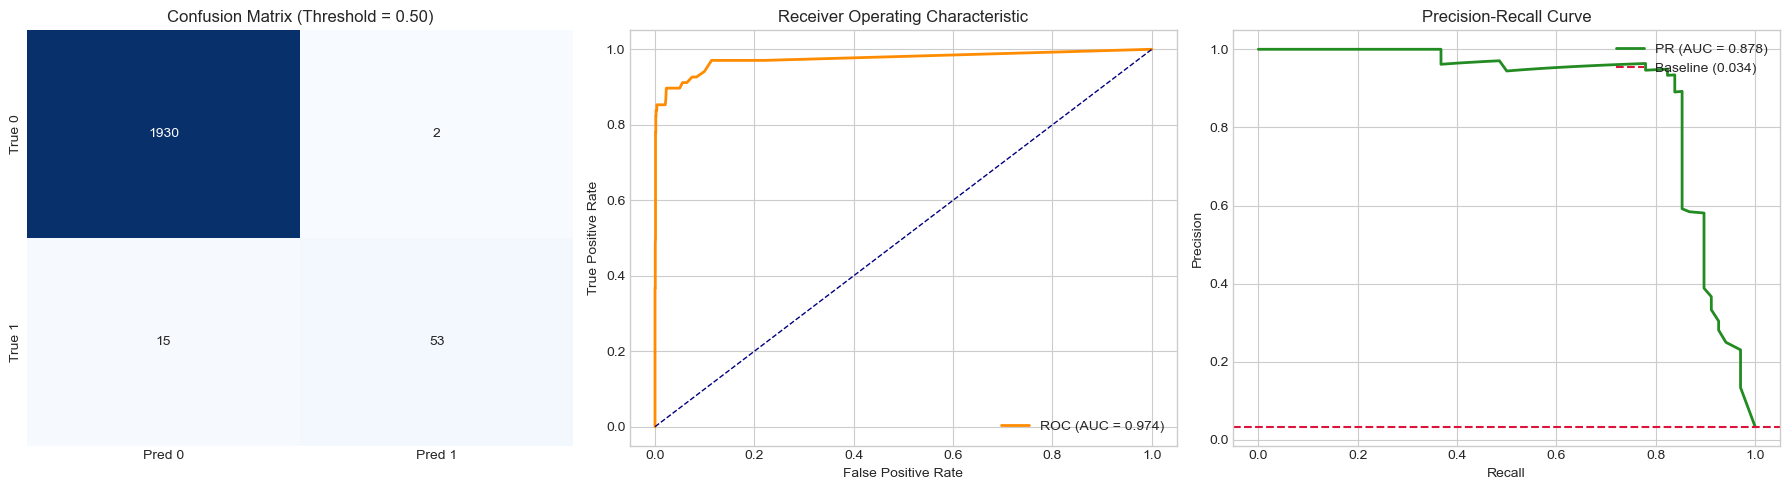

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[0],
            xticklabels=['Pred 0', 'Pred 1'], yticklabels=['True 0', 'True 1'])
axes[0].set_title('Confusion Matrix (Threshold = 0.50)')

# 2. ROC Curve
fpr, tpr, _ = roc_curve(y_test, y_prob)
axes[1].plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC (AUC = {roc_auc_score(y_test, y_prob):.3f})')
axes[1].plot([0, 1], [0, 1], color='navy', lw=1, linestyle='--')
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].set_title('Receiver Operating Characteristic')
axes[1].legend(loc='lower right')

# 3. Precision-Recall Curve
prec, rec, _ = precision_recall_curve(y_test, y_prob)
axes[2].plot(rec, prec, color='forestgreen', lw=2, label=f'PR (AUC = {average_precision_score(y_test, y_prob):.3f})')
axes[2].axhline(y=y_test.mean(), color='crimson', linestyle='--', label=f'Baseline ({y_test.mean():.3f})')
axes[2].set_xlabel('Recall')
axes[2].set_ylabel('Precision')
axes[2].set_title('Precision-Recall Curve')
axes[2].legend(loc='upper right')

plt.tight_layout()
plt.show()

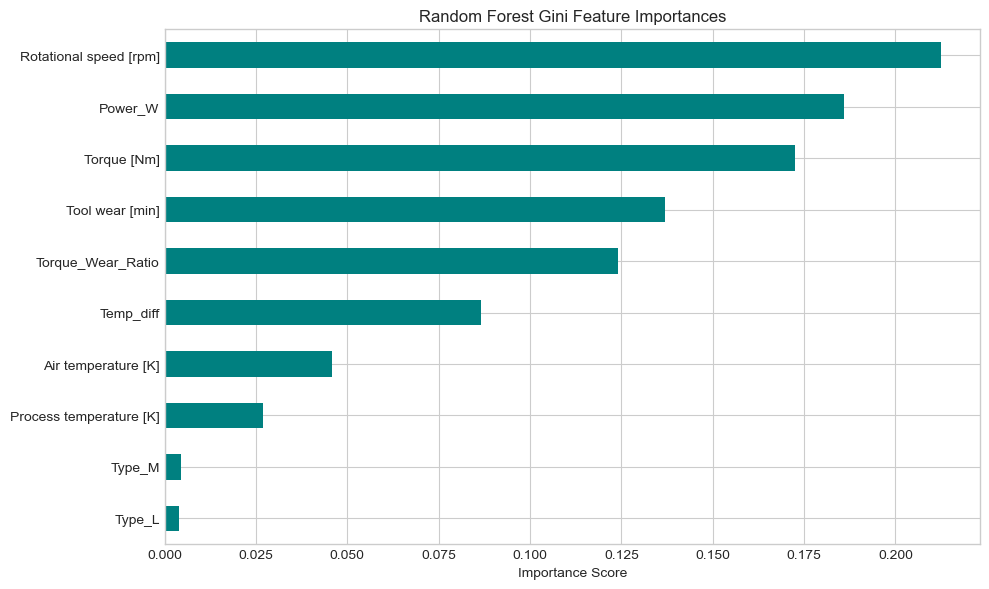

In [12]:
# Extract feature names after one-hot encoding
cat_features = final_model.named_steps['prep'].named_transformers_['cat'].get_feature_names_out(categorical_cols).tolist()
all_features = numeric_cols + cat_features

# Extract importances from Random Forest
importances = final_model.named_steps['clf'].feature_importances_
feat_imp = pd.Series(importances, index=all_features).sort_values(ascending=True)

plt.figure(figsize=(10, 6))
feat_imp.plot(kind='barh', color='teal')
plt.title('Random Forest Gini Feature Importances')
plt.xlabel('Importance Score')
plt.tight_layout()
plt.show()